In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage import io
from skimage import color
from skimage import filters
from skimage import measure
from skimage import morphology
from skimage import exposure
from skimage.transform import rotate
import cv2
import numpy as np
import webcolors
from scipy.spatial import KDTree
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


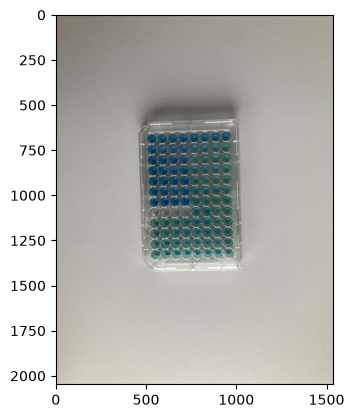

(2048, 1536, 3)
<class 'numpy.ndarray'>
uint8


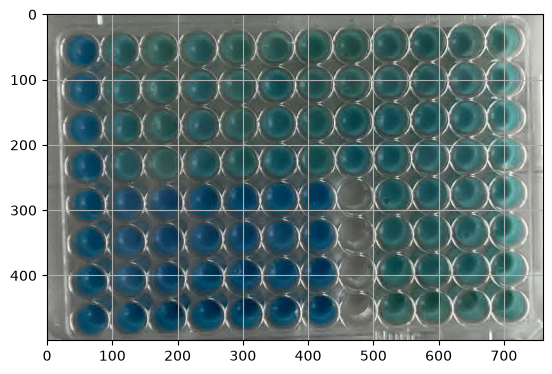

Image saved successfully.


In [26]:
image = io.imread(r"../data/raw/plate photos/plate image 1.jpg")

plt.imshow(image)
plt.show()

print(image.shape)
print(type(image))
print(image.dtype)

cropped = image[620:1380, 500:1000]
cropped = rotate(cropped, angle=90, resize=True)
plt.imshow(cropped)
plt.grid()
plt.show()

import numpy as np
from skimage import io
from pathlib import Path

output_dir = Path(r"../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

cropped_to_save = (np.clip(cropped, 0, 1) * 255).astype(np.uint8)

io.imsave(
    output_dir / "cropped_plate_image.jpg",
    cropped_to_save
)

print("Image saved successfully.")

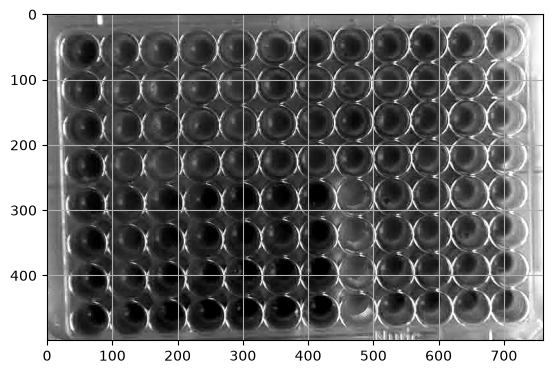

In [27]:
gray = color.rgb2gray(cropped)

p2, p98 = np.percentile(gray, (2, 98))

gray_contrast = exposure.rescale_intensity(gray, in_range=(p2, p98))

plt.imshow(gray_contrast, cmap='gray')
plt.grid()
plt.show()

In [28]:
# Convert to gray-scale and reduce noise https://medium.com/codex/well-and-color-detection-of-pcr-plate-using-python-and-opencv-edb0aaa0ef9d
if cropped.dtype.kind == 'f':
    cropped_uint8 = (np.clip(cropped, 0, 1) * 255).astype(np.uint8)
else:
    cropped_uint8 = cropped.astype(np.uint8)
gray = cv2.cvtColor(cropped_uint8, cv2.COLOR_RGB2GRAY)
img_blur = cv2.medianBlur(gray, 5)
circles = cv2.HoughCircles(img_blur,
                           cv2.HOUGH_GRADIENT,
                           1,
                           cropped.shape[0]/64,
                           param1=200,
                           param2=10,
                           minRadius=14,
                           maxRadius=15
                          )
# Draw detected circles
if circles is not None:
    circles = np.uint16(np.around(circles))
    for i in circles[0, :96]:
        
        # outer circle
        ## cv2.circle(image, center_coordinates, radius, color, thickness)
        cv2.circle(cropped_uint8, (i[0], i[1]), i[2], (0, 0, 0), 2)
        
        # rgb values
        b = cropped_uint8[i[1], i[0], 0]
        g = cropped_uint8[i[1], i[0], 1]
        r = cropped_uint8[i[1], i[0], 2]
        
        color_name = convert_rgb_to_color_name((r, g, b))
        
        mapped_cell = {
            "well_coordinates": (i[0], i[1]),
            "well_color": color_name
        }
        mapped_cells_list.append(mapped_cell)
        
        # inner circle
        cv2.circle(cropped_uint8, (i[0], i[1]), 1, (0, 0, 255), 2)


Number of circles detected: 96
Average circle colors (RGB):
{'center': (705, 158), 'radius': 29, 'avg_rgb': (138, 141, 101)}
{'center': (529, 105), 'radius': 29, 'avg_rgb': (93, 95, 66)}
{'center': (643, 160), 'radius': 29, 'avg_rgb': (107, 107, 70)}
{'center': (411, 164), 'radius': 29, 'avg_rgb': (84, 87, 52)}
{'center': (646, 334), 'radius': 29, 'avg_rgb': (106, 107, 71)}
{'center': (644, 218), 'radius': 29, 'avg_rgb': (109, 109, 75)}
{'center': (706, 217), 'radius': 29, 'avg_rgb': (138, 142, 105)}
{'center': (410, 105), 'radius': 29, 'avg_rgb': (84, 89, 59)}
{'center': (475, 280), 'radius': 29, 'avg_rgb': (95, 100, 94)}
{'center': (586, 159), 'radius': 29, 'avg_rgb': (94, 93, 57)}
{'center': (409, 51), 'radius': 29, 'avg_rgb': (85, 92, 60)}
{'center': (652, 392), 'radius': 29, 'avg_rgb': (104, 105, 69)}
{'center': (643, 41), 'radius': 28, 'avg_rgb': (99, 104, 74)}
{'center': (466, 106), 'radius': 29, 'avg_rgb': (88, 93, 65)}
{'center': (645, 101), 'radius': 29, 'avg_rgb': (108, 109,

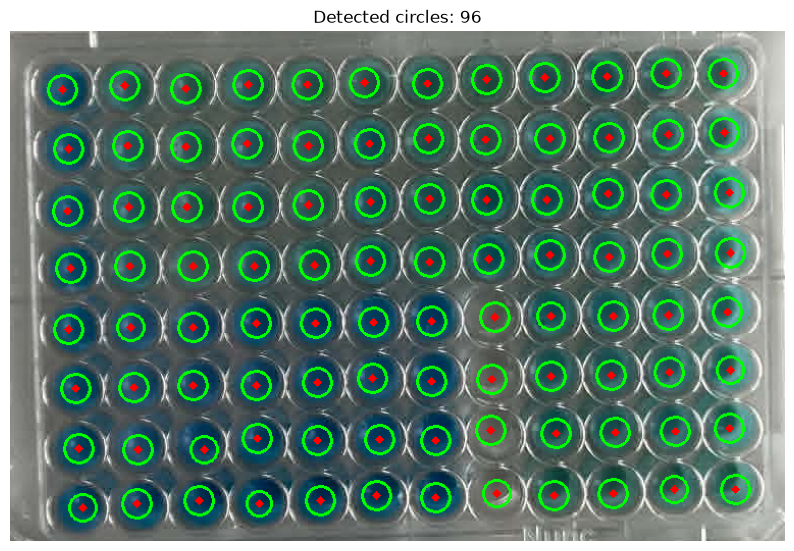

In [29]:
# Convert to uint8 if needed
if cropped.dtype.kind == 'f':
    cropped_uint8 = (np.clip(cropped, 0, 1) * 255).astype(np.uint8)
else:
    cropped_uint8 = cropped.astype(np.uint8)

# Convert to grayscale
gray = cv2.cvtColor(cropped_uint8, cv2.COLOR_RGB2GRAY)

# Reduce noise
img_blur = cv2.medianBlur(gray, 5)

# Detect circles
circles = cv2.HoughCircles(
    img_blur,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=45,
    param1=50,
    param2=15,
    minRadius=25,
    maxRadius=30
)

# Create copy for visualization
result = cropped_uint8.copy()
average_colors = []

if circles is not None:
    circles = np.uint16(np.around(circles))
    n_circles = circles.shape[1]
    print(f"Number of circles detected: {n_circles}")

    # Draw circles and compute average RGB for each circle
    for circle in circles[0, :]:
        x, y, r = circle
        r_small = int(r * 0.5)

        # Create a mask for the circle interior
        mask = np.zeros(gray.shape, dtype=np.uint8)
        cv2.circle(mask, (x, y), r, 255, thickness=-1)

        # Compute mean BGR values inside the circle using the mask
        mean_bgr = cv2.mean(cropped_uint8, mask=mask)[:3]
        avg_rgb = (int(round(mean_bgr[2])), int(round(mean_bgr[1])), int(round(mean_bgr[0])))
        average_colors.append({
            "center": (int(x), int(y)),
            "radius": int(r),
            "avg_rgb": avg_rgb
        })

        # Draw outer circle (green)
        cv2.circle(
            result,
            (x, y),
            r_small,
            (0, 255, 0),
            2
        )

        # Draw center point (red)
        cv2.circle(
            result,
            (x, y),
            2,
            (255, 0, 0),
            3
        )

    print("Average circle colors (RGB):")
    for info in average_colors:
        print(info)

    # Display result
    plt.figure(figsize=(10, 10))
    plt.imshow(result)
    plt.title(f"Detected circles: {n_circles}")
    plt.axis("off")
    plt.show()

else:
    print("No circles detected")


c:\Users\ninacor\AppData\Local\miniconda3\envs\image_analysis_evn\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ninacor\AppData\Local\miniconda3\envs\image_analysis_evn\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Explained variance ratio: [0.89564745 0.08967782]


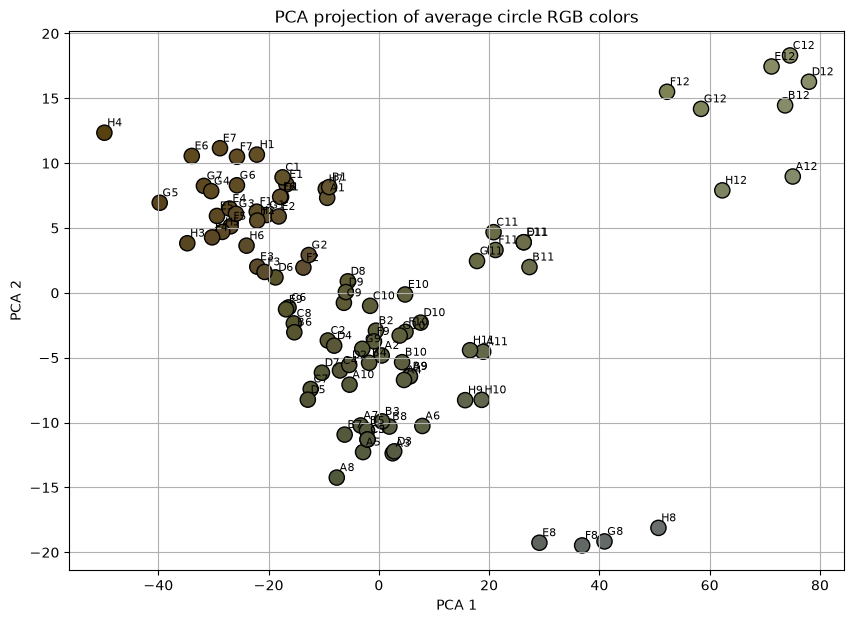

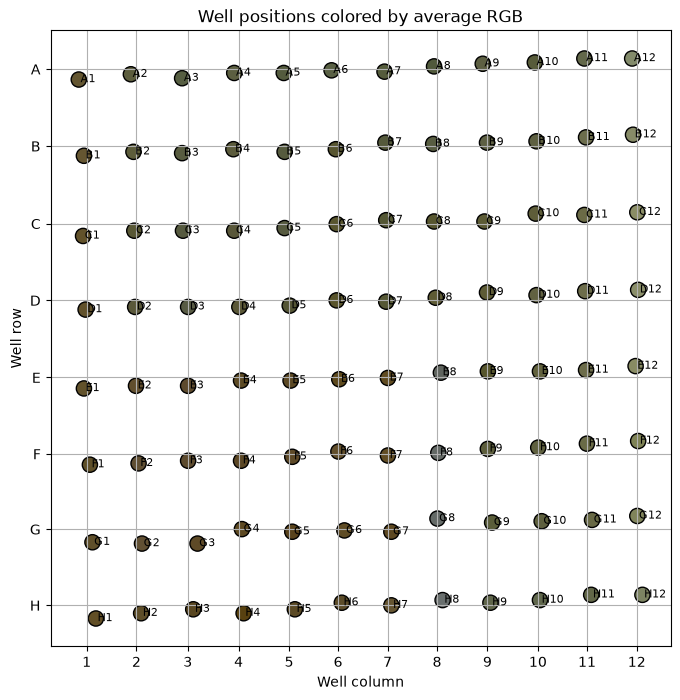

In [30]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Build a DataFrame from the detected circle colors and positions
if len(average_colors) == 0:
    print("No average color data available. Run the detection cell first.")
else:
    df_colors = pd.DataFrame(average_colors)
    df_colors[['x', 'y']] = pd.DataFrame(
        df_colors['center'].tolist(),
        index=df_colors.index
    )
    df_colors[['r', 'g', 'b']] = pd.DataFrame(
        df_colors['avg_rgb'].tolist(),
        index=df_colors.index
    )
    df_colors['color_hex'] = df_colors.apply(
        lambda row: '#%02x%02x%02x' % (row['r'], row['g'], row['b']),
        axis=1
    )

    # Assign each circle to a grid column and row.
    x_model = KMeans(n_clusters=12, random_state=0, n_init=10).fit(df_colors[['x']])
    y_model = KMeans(n_clusters=8, random_state=0, n_init=10).fit(df_colors[['y']])

    # Order columns left-to-right and rows top-to-bottom.
    x_centers = x_model.cluster_centers_.ravel()
    y_centers = y_model.cluster_centers_.ravel()
    x_order = sorted(range(12), key=lambda i: x_centers[i])
    y_order = sorted(range(8), key=lambda i: y_centers[i])

    column_number = {
        cluster: position + 1
        for position, cluster in enumerate(x_order)
    }
    row_letter = {
        cluster: "ABCDEFGH"[position]
        for position, cluster in enumerate(y_order)
    }

    df_colors['well'] = [
        f"{row_letter[row]}{column_number[col]}"
        for col, row in zip(x_model.labels_, y_model.labels_)
    ]

    # Run PCA on the RGB values
    pca = PCA(n_components=2)
    rgb_values = df_colors[['r', 'g', 'b']].astype(float)
    df_colors[['pca1', 'pca2']] = pca.fit_transform(rgb_values)

    print('Explained variance ratio:', pca.explained_variance_ratio_)

    # Plot PCA projection of colors, labeled by well
    plt.figure(figsize=(10, 7))
    plt.scatter(
        df_colors['pca1'],
        df_colors['pca2'],
        c=rgb_values.values / 255.0,
        s=120,
        edgecolor='k'
    )
    for _, row in df_colors.iterrows():
        plt.text(
            row['pca1'] + 0.5,
            row['pca2'] + 0.5,
            row['well'],
            fontsize=8
        )
    plt.xlabel('PCA 1')
    plt.ylabel('PCA 2')
    plt.title('PCA projection of average circle RGB colors')
    plt.grid(True)
    plt.show()

    # Plot well positions colored by average RGB
    plt.figure(figsize=(8, 8))
    plt.scatter(
        df_colors['x'],
        df_colors['y'],
        c=rgb_values.values / 255.0,
        s=120,
        edgecolor='k'
    )
    for _, row in df_colors.iterrows():
        plt.text(row['x'] + 2, row['y'] + 2, row['well'], fontsize=8)

    plt.xticks([x_centers[i] for i in x_order], range(1, 13))
    plt.yticks([y_centers[i] for i in y_order], list("ABCDEFGH"))
    plt.gca().invert_yaxis()
    plt.xlabel('Well column')
    plt.ylabel('Well row')
    plt.title('Well positions colored by average RGB')
    plt.grid(True)
    plt.show()

In [32]:
from pathlib import Path
import numpy as np

# Create the synthetic cube as float32 to reduce memory use.
wavelengths = np.arange(400, 1001, 2, dtype=np.float32)
height, width = cropped_uint8.shape[:2]
n_bands = wavelengths.size

r = cropped_uint8[:, :, 0].astype(np.float32)
g = cropped_uint8[:, :, 1].astype(np.float32)
b = cropped_uint8[:, :, 2].astype(np.float32)

cube = np.empty((height, width, n_bands), dtype=np.float32)
temp = np.empty((height, width), dtype=np.float32)

# Precompute the synthetic channel responses at each wavelength.
blue_profile = np.exp(-((wavelengths - 450.0) ** 2) / (2.0 * 40.0 ** 2))
green_profile = np.exp(-((wavelengths - 550.0) ** 2) / (2.0 * 50.0 ** 2))
red_profile = np.exp(-((wavelengths - 650.0) ** 2) / (2.0 * 60.0 ** 2))

for i in range(n_bands):
    band = cube[:, :, i]

    np.multiply(b, blue_profile[i], out=band)
    np.multiply(g, green_profile[i], out=temp)
    np.add(band, temp, out=band)
    np.multiply(r, red_profile[i], out=temp)
    np.add(band, temp, out=band)

# Normalize in place instead of allocating a second full-sized cube.
maximum = cube.max()
if maximum <= 0:
    raise ValueError("Cannot normalize a zero-valued hyperspectral cube.")
cube /= maximum

print("Cube shape:", cube.shape)
print("Cube dtype:", cube.dtype)

# Save the binary cube and its ENVI header.
output_dir = Path(r"..\data\raw\spectral data")
output_dir.mkdir(parents=True, exist_ok=True)

raw_file = output_dir / "plate_cube.raw"
hdr_file = output_dir / "plate_cube.hdr"

# The cube is stored in rows, columns, bands order: ENVI BIP interleave.
# <f4 specifies little-endian 32-bit floating point, matching the header.
cube.astype("<f4", copy=False).tofile(raw_file)

wavelength_text = ",\n  ".join(f"{value:g}" for value in wavelengths)
header_text = (
    "ENVI\n"
    "description = {Synthetic hyperspectral plate cube}\n"
    f"samples = {width}\n"
    f"lines = {height}\n"
    f"bands = {n_bands}\n"
    "header offset = 0\n"
    "file type = ENVI Standard\n"
    "data type = 4\n"
    "interleave = bip\n"
    "sensor type = Unknown\n"
    "byte order = 0\n"
    "wavelength units = Nanometers\n"
    f"wavelength = {{{wavelength_text}}}\n"
)

hdr_file.write_text(header_text, encoding="ascii")

print(f"Saved binary data: {raw_file}")
print(f"Saved ENVI header: {hdr_file}")

Cube shape: (500, 760, 301)
Cube dtype: float32
Saved binary data: ..\data\raw\spectral data\plate_cube.raw
Saved ENVI header: ..\data\raw\spectral data\plate_cube.hdr


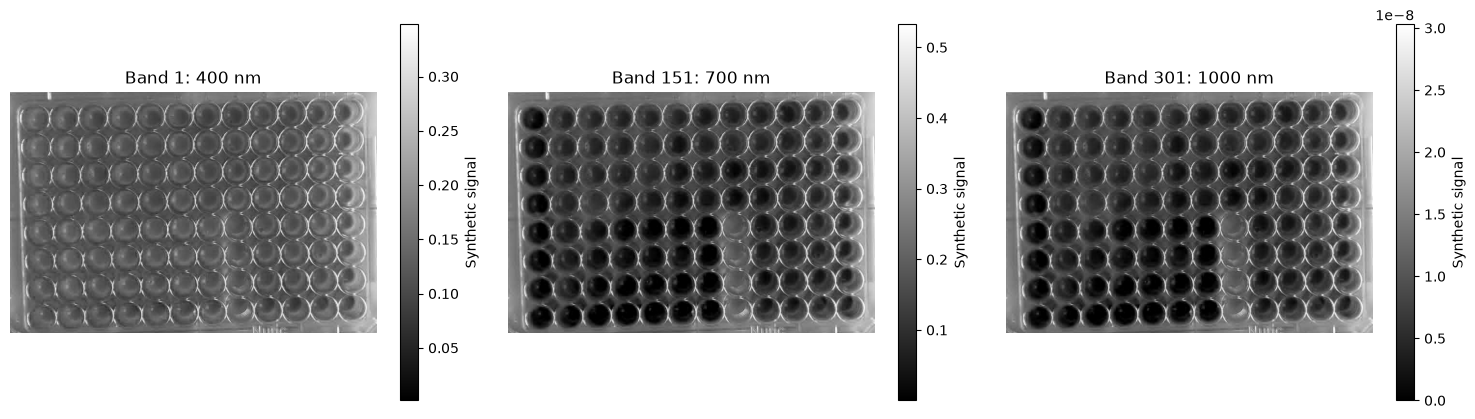

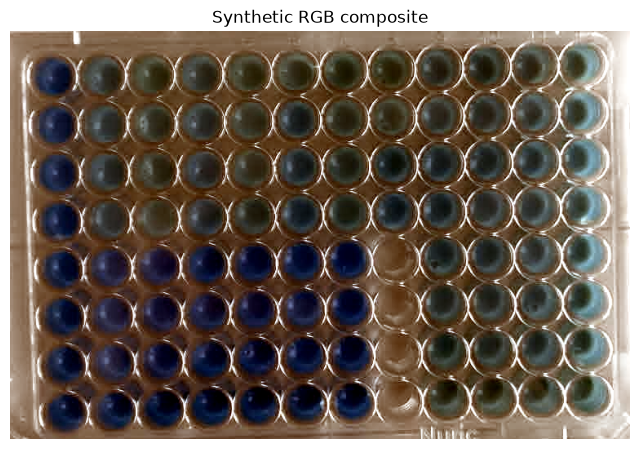

RGB bands use wavelengths: [650. 550. 450.]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

cube_array = np.asarray(cube)
wavelengths = np.asarray(wavelengths, dtype=float)

if cube_array.ndim != 3:
    raise ValueError(f"Expected cube shaped (rows, columns, bands); got {cube_array.shape}.")

height, width, n_bands = cube_array.shape
if wavelengths.size != n_bands:
    raise ValueError(f"Found {n_bands} bands but {wavelengths.size} wavelengths.")

# View the first, middle, and last bands.
band_indices = sorted(set((0, n_bands // 2, n_bands - 1)))
fig, axes = plt.subplots(
    1, len(band_indices),
    figsize=(5 * len(band_indices), 5),
    squeeze=False
)

for ax, band_index in zip(axes.ravel(), band_indices):
    image = ax.imshow(cube_array[:, :, band_index], cmap="gray")
    ax.set_title(f"Band {band_index + 1}: {wavelengths[band_index]:.0f} nm")
    ax.set_axis_off()
    fig.colorbar(image, ax=ax, shrink=0.8, label="Synthetic signal")

fig.tight_layout()
plt.show()

# Optional RGB-style view using the nearest bands to red, green, and blue wavelengths.
target_wavelengths = (650, 550, 450)
rgb_indices = [
    int(np.abs(wavelengths - target).argmin())
    for target in target_wavelengths
]
rgb = np.stack(
    [cube_array[:, :, index] for index in rgb_indices],
    axis=-1
).astype(float)

# Stretch each channel separately for display.
low, high = np.nanpercentile(rgb, (2, 98), axis=(0, 1))
scale = high - low
scale[scale == 0] = 1.0
rgb = np.clip((rgb - low) / scale, 0, 1)
rgb = np.nan_to_num(rgb, nan=0.0, posinf=1.0, neginf=0.0)

plt.figure(figsize=(8, 8))
plt.imshow(rgb)
plt.title("Synthetic RGB composite")
plt.axis("off")
plt.show()

print("RGB bands use wavelengths:", wavelengths[rgb_indices])

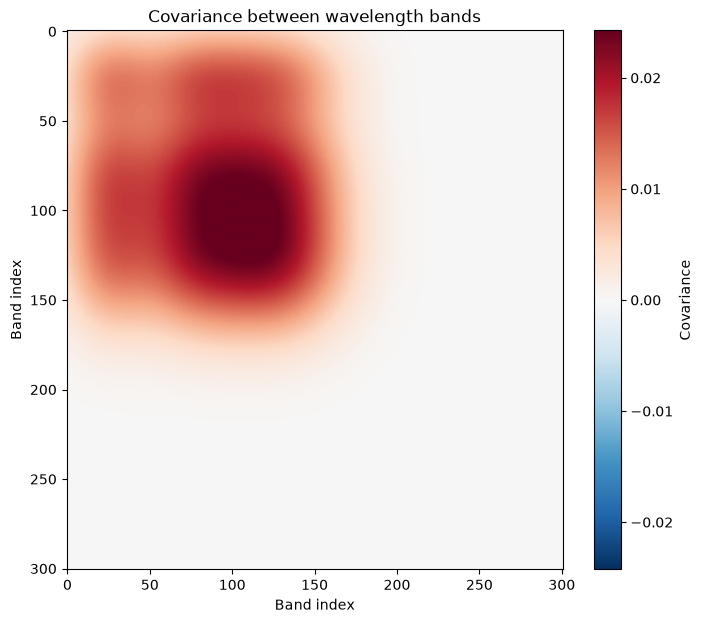

Variance explained by first 3 PCs: [0.96458175 0.03351833 0.00189992]


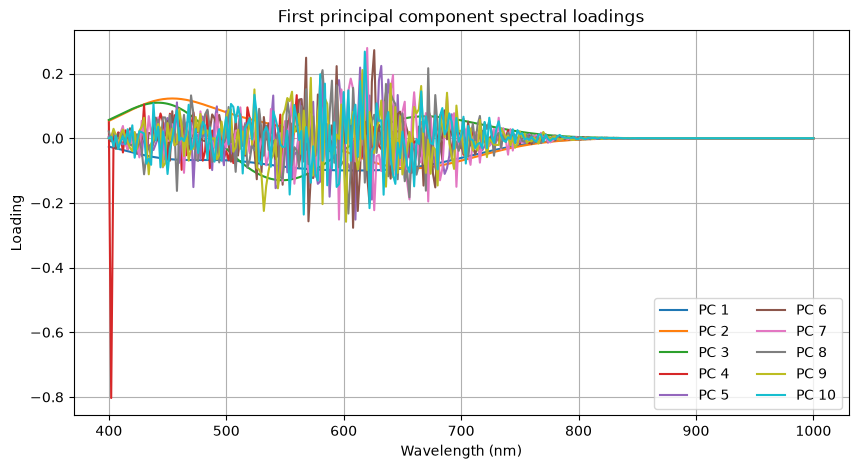

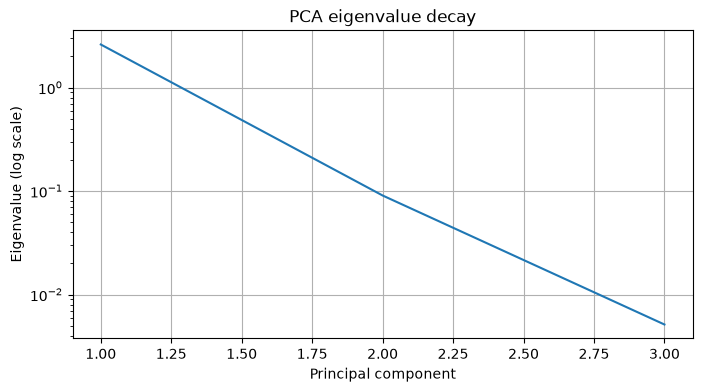

In [ ]:
flat = cube_array.reshape(-1, n_bands)
valid_indices = np.flatnonzero(np.isfinite(flat).all(axis=1))

if valid_indices.size < 2:
    raise ValueError("Need at least two pixels with finite values in every band.")

sample_indices = valid_indices[::100]
X_sample = flat[sample_indices]
mean_spectrum = X_sample.mean(axis=0)
covariance = np.cov(X_sample, rowvar=False)

# Show positive and negative covariance with a symmetric color scale.
color_limit = np.percentile(np.abs(covariance), 98)
if color_limit == 0:
    color_limit = 1.0

plt.figure(figsize=(8, 7))
plt.imshow(
    covariance,
    cmap="RdBu_r",
    vmin=-color_limit,
    vmax=color_limit,
    aspect="auto"
)
plt.colorbar(label="Covariance")
plt.title("Covariance between wavelength bands")
plt.xlabel("Band index")
plt.ylabel("Band index")
plt.show()

# Eigenvectors are PCA loadings; eigenvalues determine explained variance.
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = np.maximum(eigenvalues[order], 0)
eigenvectors = eigenvectors[:, order]

total_variance = eigenvalues.sum()
if not np.isfinite(total_variance) or total_variance <= 0:
    raise ValueError("PCA cannot be computed because the sampled cube has no variance.")

explained_variance = eigenvalues / total_variance
print("Variance explained by first 3 PCs:", explained_variance[:3])

plt.figure(figsize=(10, 5))
for component_index in range(min(10, n_bands)):
    plt.plot(
        wavelengths,
        eigenvectors[:, component_index],
        label=f"PC {component_index + 1}"
    )

plt.xlabel("Wavelength (nm)")
plt.ylabel("Loading")
plt.title("First principal component spectral loadings")
plt.legend(ncol=2)
plt.grid(True)
plt.show()

# Ignore tiny values likely due only to numerical precision in the log-scale plot.
visible = eigenvalues > eigenvalues[0] * 1e-12
plt.figure(figsize=(8, 4))
plt.semilogy(
    np.arange(1, n_bands + 1)[visible],
    eigenvalues[visible]
)
plt.xlabel("Principal component")
plt.ylabel("Eigenvalue (log scale)")
plt.title("PCA eigenvalue decay")
plt.grid(True)
plt.show()

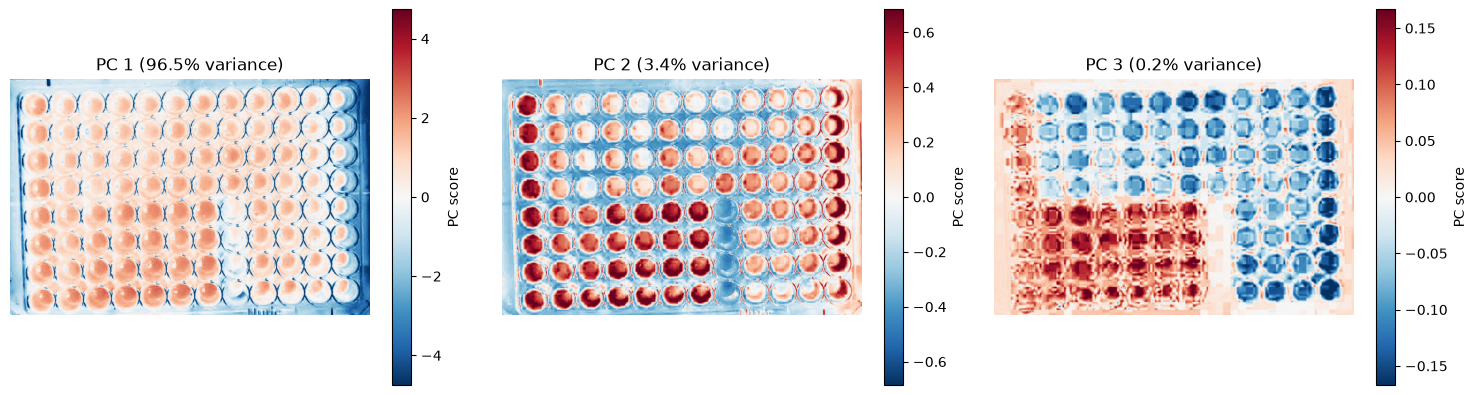

In [ ]:
n_components = min(3, n_bands)
projection = np.full(
    (height * width, n_components),
    np.nan,
    dtype=np.float32
)

for start in range(0, valid_indices.size, 50_000):
    pixel_indices = valid_indices[start:start + 50_000]
    batch = flat[pixel_indices]
    projection[pixel_indices] = (
        (batch - mean_spectrum) @ eigenvectors[:, :n_components]
    )

projection = projection.reshape(height, width, n_components)

fig, axes = plt.subplots(
    1, n_components,
    figsize=(5 * n_components, 5),
    squeeze=False
)

for component_index, ax in enumerate(axes.ravel()):
    component = projection[:, :, component_index]
    finite_values = component[np.isfinite(component)]
    limit = (
        np.percentile(np.abs(finite_values), 98)
        if finite_values.size else 1.0
    )
    if not np.isfinite(limit) or limit == 0:
        limit = 1.0

    image = ax.imshow(
        component,
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit
    )
    ax.set_title(
        f"PC {component_index + 1} "
        f"({explained_variance[component_index]:.1%} variance)"
    )
    ax.set_axis_off()
    fig.colorbar(image, ax=ax, shrink=0.8, label="PC score")

fig.tight_layout()
plt.show()

Calculated mean spectra for 96 wells.


,pixel_count,400.0,402.0,404.0,406.0,408.0
well,,,,,,
A1,2629,0.136455,0.145252,0.154245,0.163403,0.172691
A10,2453,0.119126,0.126838,0.134728,0.142769,0.150931
A11,2453,0.135481,0.144254,0.153229,0.162376,0.171663
A12,2629,0.179502,0.191130,0.203026,0.215151,0.227461
A2,2453,0.125755,0.133891,0.142214,0.150694,0.159302
...,...,...,...,...,...,...
H5,2629,0.123706,0.131673,0.139814,0.148102,0.156506
H6,2629,0.124552,0.132578,0.140781,0.149132,0.157602
H7,2629,0.137224,0.146068,0.155107,0.164311,0.173645


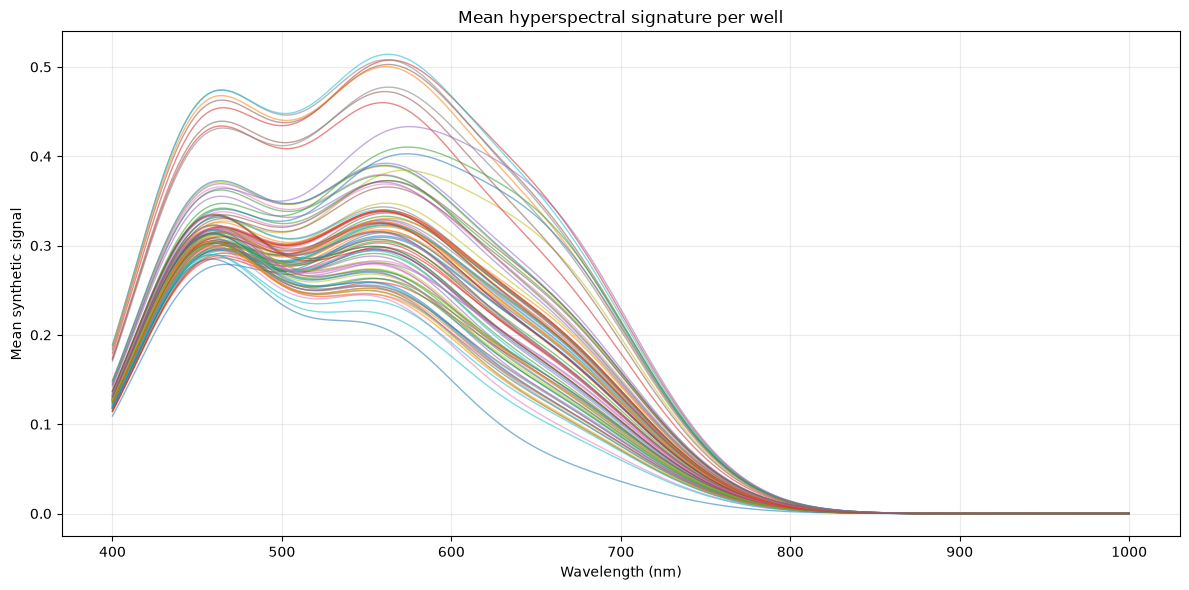

PCA explained variance ratio: [0.94554735 0.04970649]


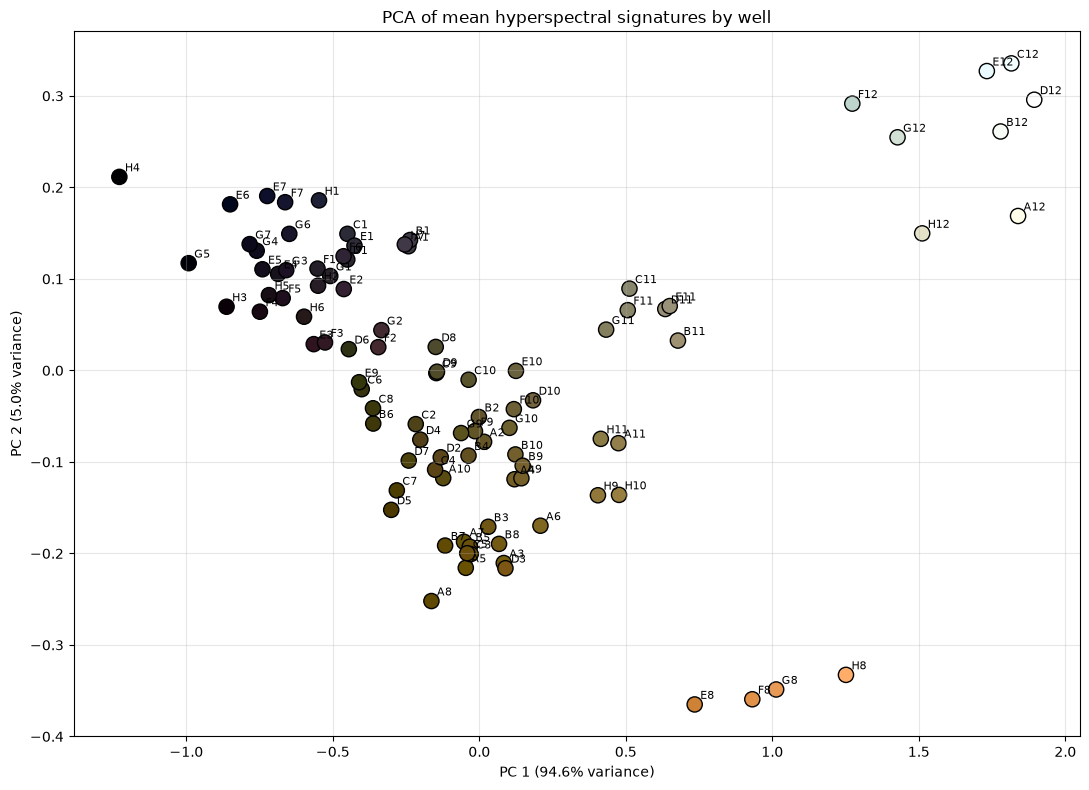

Pseudo-RGB display uses wavelengths: [650. 550. 450.]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

cube_array = np.asarray(cube)
wavelengths = np.asarray(wavelengths, dtype=float)

required_columns = {"well", "x", "y", "radius"}
if not required_columns.issubset(df_colors.columns):
    raise ValueError(f"df_colors must contain these columns: {sorted(required_columns)}")
if cube_array.ndim != 3:
    raise ValueError(f"Expected cube shaped (rows, columns, bands); got {cube_array.shape}.")

height, width, n_bands = cube_array.shape
if wavelengths.size != n_bands:
    raise ValueError(f"Found {n_bands} bands but {wavelengths.size} wavelengths.")

# Average all valid pixel spectra inside each detected well.
row_grid, col_grid = np.ogrid[:height, :width]
well_names = []
mean_spectra = []
pixel_counts = []

for well_name, circles in df_colors.groupby("well", sort=True):
    well_mask = np.zeros((height, width), dtype=bool)

    # Combine circles assigned to the same well into one mask.
    for circle in circles.itertuples(index=False):
        center_x = int(round(circle.x))
        center_y = int(round(circle.y))
        radius = int(round(circle.radius))

        if radius >= 1:
            well_mask |= (
                (col_grid - center_x) ** 2 + (row_grid - center_y) ** 2
                <= radius ** 2
            )

    pixels = cube_array[well_mask]
    pixels = pixels[np.isfinite(pixels).all(axis=1)]

    if pixels.shape[0] == 0:
        raise ValueError(f"No valid cube pixels found inside well {well_name!r}.")

    well_names.append(str(well_name))
    mean_spectra.append(pixels.mean(axis=0))
    pixel_counts.append(pixels.shape[0])

well_spectra = np.stack(mean_spectra)

# Table of mean spectra: one row per well and one column per wavelength.
well_spectra_df = pd.DataFrame(
    well_spectra,
    index=well_names,
    columns=wavelengths
)
well_spectra_df.index.name = "well"
well_spectra_df.insert(0, "pixel_count", pixel_counts)

print(f"Calculated mean spectra for {len(well_names)} wells.")
display(well_spectra_df.iloc[:, :6])  # Pixel count and first five wavelengths

# Plot the mean spectrum for each well.
plt.figure(figsize=(12, 6))
for i, well_name in enumerate(well_names):
    plt.plot(wavelengths, well_spectra[i], alpha=0.55, linewidth=1, label=well_name)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Mean synthetic signal")
plt.title("Mean hyperspectral signature per well")
if len(well_names) <= 20:
    plt.legend(title="Well", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

# PCA is performed on the full mean spectra, not just three RGB bands.
if len(well_names) < 2:
    raise ValueError("PCA requires at least two wells with valid spectra.")

pca = PCA(n_components=2)
well_pcs = pca.fit_transform(well_spectra)
print("PCA explained variance ratio:", pca.explained_variance_ratio_)

# Color each PCA point by a display-only pseudo-RGB from the nearest 650, 550, 450 nm bands.
target_wavelengths = (650, 550, 450)
rgb_indices = [
    int(np.abs(wavelengths - target).argmin())
    for target in target_wavelengths
]
well_rgb = well_spectra[:, rgb_indices].astype(float)

# Stretch each channel across wells so the points are visible in the plot.
low, high = np.percentile(well_rgb, (2, 98), axis=0)
channel_scale = high - low
channel_scale[channel_scale == 0] = 1.0
well_rgb = np.clip((well_rgb - low) / channel_scale, 0, 1)

plt.figure(figsize=(11, 8))
plt.scatter(
    well_pcs[:, 0],
    well_pcs[:, 1],
    c=well_rgb,
    s=120,
    edgecolors="black"
)

for i, well_name in enumerate(well_names):
    plt.annotate(
        well_name,
        (well_pcs[i, 0], well_pcs[i, 1]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("PCA of mean hyperspectral signatures by well")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Pseudo-RGB display uses wavelengths:", wavelengths[rgb_indices])

In [ ]:
import pandas as pd

# ==========================================
# Create well names
# ==========================================

rows = "ABCDEFGH"
cols = range(1, 13)

plate = []

for row in rows:
    for col in cols:

        well = f"{row}{col}"

        composition = {
            "GCA_000011845.1": 0,  # S. thermophilus CNRZ1066
            "GCA_000014485.1": 0,  # S. thermophilus LMD-9
            "GCA_000698885.1": 0,  # S. thermophilus ASCC1275
            "GCA_000056065.1": 0,  # L. bulgaricus
            "GCA_000236475.1": 0   # L. lactis A76
        }

        # ----------------------------------
        # Column 1: Blank control
        # ----------------------------------

        if col == 1:
            pass

        # ----------------------------------
        # Pure cultures
        # ----------------------------------

        elif col == 2:
            composition["GCA_000011845.1"] = 100

        elif col == 3:
            composition["GCA_000014485.1"] = 100

        elif col == 4:
            composition["GCA_000698885.1"] = 100

        elif col == 5:
            composition["GCA_000056065.1"] = 100

        elif col == 6:
            composition["GCA_000236475.1"] = 100

        # ----------------------------------
        # Two-strain mixtures
        # ----------------------------------

        elif col == 7:
            composition["GCA_000011845.1"] = 50
            composition["GCA_000014485.1"] = 50

        elif col == 8:
            composition["GCA_000011845.1"] = 50
            composition["GCA_000698885.1"] = 50

        elif col == 9:
            composition["GCA_000014485.1"] = 50
            composition["GCA_000698885.1"] = 50

        # ----------------------------------
        # Three S. thermophilus strains
        # ----------------------------------

        elif col == 10:
            composition["GCA_000011845.1"] = 34
            composition["GCA_000014485.1"] = 33
            composition["GCA_000698885.1"] = 33

        # ----------------------------------
        # Yogurt culture
        # ----------------------------------

        elif col == 11:
            composition["GCA_000698885.1"] = 60
            composition["GCA_000056065.1"] = 40

        # ----------------------------------
        # Cheese culture
        # ----------------------------------

        elif col == 12:
            composition["GCA_000236475.1"] = 60
            composition["GCA_000011845.1"] = 20
            composition["GCA_000014485.1"] = 20

        plate.append({
            "well": well,
            **composition
        })

# ==========================================
# Create dataframe
# ==========================================

plate_df = pd.DataFrame(plate)

# Check percentages

plate_df["total_percent"] = (
    plate_df["GCA_000011845.1"]
    + plate_df["GCA_000014485.1"]
    + plate_df["GCA_000698885.1"]
    + plate_df["GCA_000056065.1"]
    + plate_df["GCA_000236475.1"]
)

print(plate_df.head())
print()
print(plate_df["total_percent"].value_counts())

# ==========================================
# Save
# ==========================================

plate_df.to_csv(
    r"..\data\raw\plate information\plate_design.csv",
    index=False
)

print("Plate design saved successfully.")

  well  GCA_000011845.1  GCA_000014485.1  GCA_000698885.1  GCA_000056065.1  \
0   A1                0                0                0                0   
1   A2              100                0                0                0   
2   A3                0              100                0                0   
3   A4                0                0              100                0   
4   A5                0                0                0              100   

   GCA_000236475.1  total_percent  
0                0              0  
1                0            100  
2                0            100  
3                0            100  
4                0            100  

total_percent
100    88
0       8
Name: count, dtype: int64
Plate design saved successfully.


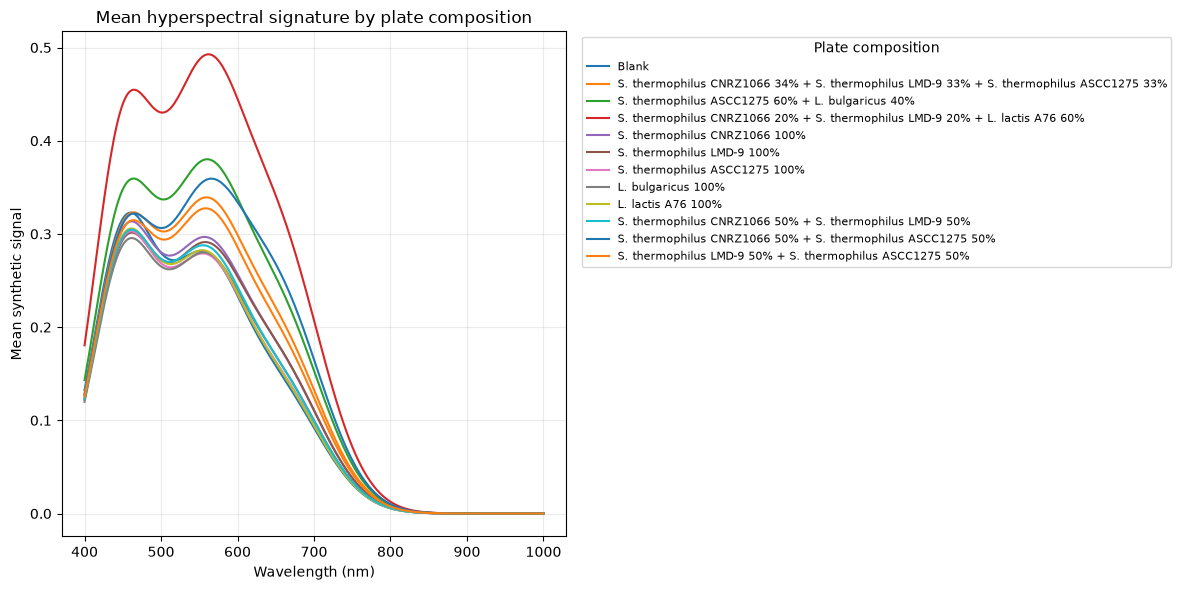

PCA explained variance ratio: [0.94554735 0.04970649]


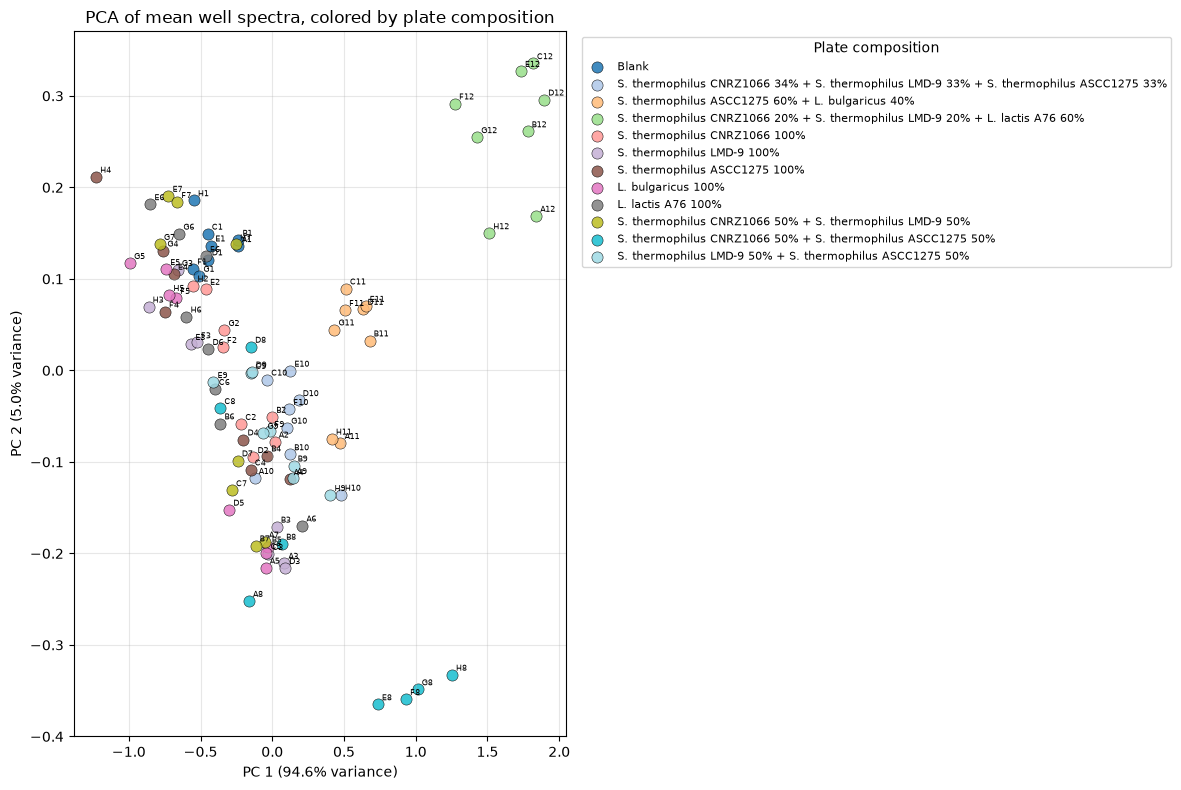

,well,composition,pixel_count
0,A1,Blank,2629
1,A10,S. thermophilus CNRZ1066 34% + S. thermophilus...,2453
2,A11,S. thermophilus ASCC1275 60% + L. bulgaricus 40%,2453
3,A12,S. thermophilus CNRZ1066 20% + S. thermophilus...,2629
4,A2,S. thermophilus CNRZ1066 100%,2453


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Load the plate design and identify its strain-percentage columns.
plate_df = pd.read_csv(r"..\data\raw\plate information\plate_design.csv")
strain_columns = [
    column for column in plate_df.columns
    if column.startswith("GCA_")
]
if not strain_columns:
    raise ValueError("No strain percentage columns found in the plate design.")

# Use readable labels for the strains in your plate design.
strain_names = {
    "GCA_000011845.1": "S. thermophilus CNRZ1066",
    "GCA_000014485.1": "S. thermophilus LMD-9",
    "GCA_000698885.1": "S. thermophilus ASCC1275",
    "GCA_000056065.1": "L. bulgaricus",
    "GCA_000236475.1": "L. lactis A76",
}

def describe_composition(row):
    present = [
        f"{strain_names.get(column, column)} {row[column]:g}%"
        for column in strain_columns
        if row[column] > 0
    ]
    return "Blank" if not present else " + ".join(present)

# Normalize well names before matching the measurements to the plate design.
plate_df["well"] = plate_df["well"].astype(str).str.strip().str.upper()
plate_df["composition"] = plate_df.apply(describe_composition, axis=1)

spectra_table = well_spectra_df.reset_index()
spectra_table["well"] = spectra_table["well"].astype(str).str.strip().str.upper()

if plate_df["well"].duplicated().any():
    raise ValueError("The plate-design file contains duplicate well names.")

# Add the treatment composition to each measured well.
merged = spectra_table.merge(
    plate_df[["well", *strain_columns, "composition"]],
    on="well",
    how="left",
    validate="one_to_one",
)

if merged["composition"].isna().any():
    missing_wells = merged.loc[merged["composition"].isna(), "well"].tolist()
    raise ValueError(f"No plate-design entry found for measured wells: {missing_wells}")

# Extract the wavelength columns; pixel_count and plate metadata are not PCA features.
spectral_columns = list(wavelengths)
X = merged[spectral_columns].to_numpy(dtype=float)

# Exclude any wells with incomplete spectra.
valid_rows = np.isfinite(X).all(axis=1)
if valid_rows.sum() < 2:
    raise ValueError("PCA requires at least two wells with complete spectra.")

plot_data = merged.loc[valid_rows].reset_index(drop=True)
X = X[valid_rows]

# Plot the average spectrum for each plate composition.
mean_by_composition = plot_data.groupby("composition", sort=False)[spectral_columns].mean()

plt.figure(figsize=(12, 6))
for composition, spectrum in mean_by_composition.iterrows():
    plt.plot(wavelengths, spectrum.to_numpy(), label=composition)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Mean synthetic signal")
plt.title("Mean hyperspectral signature by plate composition")
plt.legend(
    title="Plate composition",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

# Calculate PCA from each well's full average spectrum.
pca = PCA(n_components=2)
plot_data[["PC1", "PC2"]] = pca.fit_transform(X)
print("PCA explained variance ratio:", pca.explained_variance_ratio_)

# Plot PCA scores, coloring wells by their known plate composition.
compositions = plot_data["composition"].drop_duplicates().tolist()
colors = plt.get_cmap("tab20", max(len(compositions), 1))

fig, ax = plt.subplots(figsize=(12, 8))

for index, composition in enumerate(compositions):
    selected = plot_data["composition"] == composition
    ax.scatter(
        plot_data.loc[selected, "PC1"],
        plot_data.loc[selected, "PC2"],
        label=composition,
        color=colors(index),
        s=65,
        edgecolors="black",
        linewidths=0.4,
        alpha=0.85,
    )

# Label points with their well IDs.
for _, row in plot_data.iterrows():
    ax.annotate(
        row["well"],
        (row["PC1"], row["PC2"]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=6,
    )

ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("PCA of mean well spectra, colored by plate composition")
ax.grid(True, alpha=0.3)
ax.legend(
    title="Plate composition",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
)
fig.tight_layout()
plt.show()

# Check which treatment and pixel count correspond to each measured well.
display(plot_data[["well", "composition", "pixel_count"]].head())